# 04 — Prepare Toronto SOLWEIG inputs

## Purpose

This notebook converts the **building-height-enriched U of T VoxCity pilot**
into projected raster inputs suitable for SOLWEIG.

The main outputs are:

- `dsm.tif` — digital surface model: terrain + buildings;
- `cdsm.tif` — canopy surface / vegetation height;
- `dem.tif` — terrain elevation.

The rasters are written in **EPSG:32617 (UTM Zone 17N)** at approximately
**5 m resolution**, matching the Toronto pilot modelling scale.

This notebook uses the enriched VoxCity object saved by Notebook 03:

`data/toronto/interim/voxcity_enriched/UOFT_PILOT_voxcity_enriched.pkl`

**Kernel:** Python 3.12 - VoxCity

## 1. Imports and project paths

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio

from rasterio.transform import from_bounds
from rasterio.warp import (
    calculate_default_transform,
    reproject,
    Resampling,
)

from voxcity.generator import load_voxcity

HERE = Path.cwd().resolve()

if HERE.name == "notebooks_toronto_v02":
    PROJECT_ROOT = HERE.parent
elif (HERE / "notebooks_toronto_v02").exists():
    PROJECT_ROOT = HERE
else:
    PROJECT_ROOT = Path(
        "/scratch/project_2010417/paper3/heat-conditioned-accessibility"
    )

TORONTO_DATA = PROJECT_ROOT / "data" / "toronto"
TORONTO_RAW = TORONTO_DATA / "raw"
TORONTO_INTERIM = TORONTO_DATA / "interim"
TORONTO_OUTPUTS = PROJECT_ROOT / "outputs" / "toronto"

ENRICHED_DIR = (
    TORONTO_INTERIM
    / "voxcity_enriched"
)

SOLWEIG_INPUT_DIR = (
    TORONTO_INTERIM
    / "solweig"
    / "UOFT_PILOT"
)

SOLWEIG_INPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print("Project root:", PROJECT_ROOT)
print("SOLWEIG input directory:", SOLWEIG_INPUT_DIR)

Project root: /scratch/project_2010417/paper3/heat-conditioned-accessibility
SOLWEIG input directory: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/interim/solweig/UOFT_PILOT


## 2. Load the enriched VoxCity pilot

The pickle preserves the full VoxCity object, including the enriched building
grid, canopy, land cover, terrain, and spatial metadata.

In [2]:
enriched_pickle = (
    ENRICHED_DIR
    / "UOFT_PILOT_voxcity_enriched.pkl"
)

if not enriched_pickle.exists():
    raise FileNotFoundError(
        f"Enriched VoxCity pickle not found: {enriched_pickle}"
    )

vox = load_voxcity(
    enriched_pickle,
    trusted=True,
)

print("Loaded enriched VoxCity object:")
print(enriched_pickle)

Loaded enriched VoxCity object:
/scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/interim/voxcity_enriched/UOFT_PILOT_voxcity_enriched.pkl


## 3. Inspect the core VoxCity arrays

We use:

- `buildings.heights`
- `tree_canopy.top`
- `dem.elevation`

These layers should have identical horizontal dimensions.

In [3]:
building_height = np.asarray(
    vox.buildings.heights,
    dtype=np.float32,
)

canopy_top = np.asarray(
    vox.tree_canopy.top,
    dtype=np.float32,
)

dem = np.asarray(
    vox.dem.elevation,
    dtype=np.float32,
)

print("Building grid shape:", building_height.shape)
print("Canopy grid shape  :", canopy_top.shape)
print("DEM grid shape     :", dem.shape)

if not (
    building_height.shape
    == canopy_top.shape
    == dem.shape
):
    raise RuntimeError(
        "Building, canopy, and DEM grids have different shapes."
    )

Building grid shape: (408, 408)
Canopy grid shape  : (408, 408)
DEM grid shape     : (408, 408)


## 4. Build DSM, CDSM, and DEM arrays

The digital surface model is:

\[
DSM = DEM + building\ height
\]

For the current VoxCity representation, the canopy-top grid is used as the
vegetation/canopy surface supplied to SOLWEIG.

This follows the same conceptual preparation used in the Sevilla PoC while
retaining Toronto's enriched building heights.

In [4]:
# Replace non-finite values before raster export.
building_height = np.nan_to_num(
    building_height,
    nan=0.0,
    posinf=0.0,
    neginf=0.0,
)

canopy_top = np.nan_to_num(
    canopy_top,
    nan=0.0,
    posinf=0.0,
    neginf=0.0,
)

dem = np.nan_to_num(
    dem,
    nan=0.0,
    posinf=0.0,
    neginf=0.0,
)

dsm = (
    dem
    + building_height
).astype(np.float32)

cdsm = canopy_top.astype(
    np.float32
)

dem_surface = dem.astype(
    np.float32
)

print("DSM min/mean/max:")
print(
    float(np.nanmin(dsm)),
    float(np.nanmean(dsm)),
    float(np.nanmax(dsm)),
)

print("\nCDSM min/mean/max:")
print(
    float(np.nanmin(cdsm)),
    float(np.nanmean(cdsm)),
    float(np.nanmax(cdsm)),
)

print("\nDEM min/mean/max:")
print(
    float(np.nanmin(dem_surface)),
    float(np.nanmean(dem_surface)),
    float(np.nanmax(dem_surface)),
)

DSM min/mean/max:
0.0 0.48915502429008484 116.81999969482422

CDSM min/mean/max:
0.0 0.131120502948761 13.978205680847168

DEM min/mean/max:
0.0 0.0 0.0


## 5. Visualize the source surfaces before reprojection

This is an important quality-control step before writing SOLWEIG rasters.

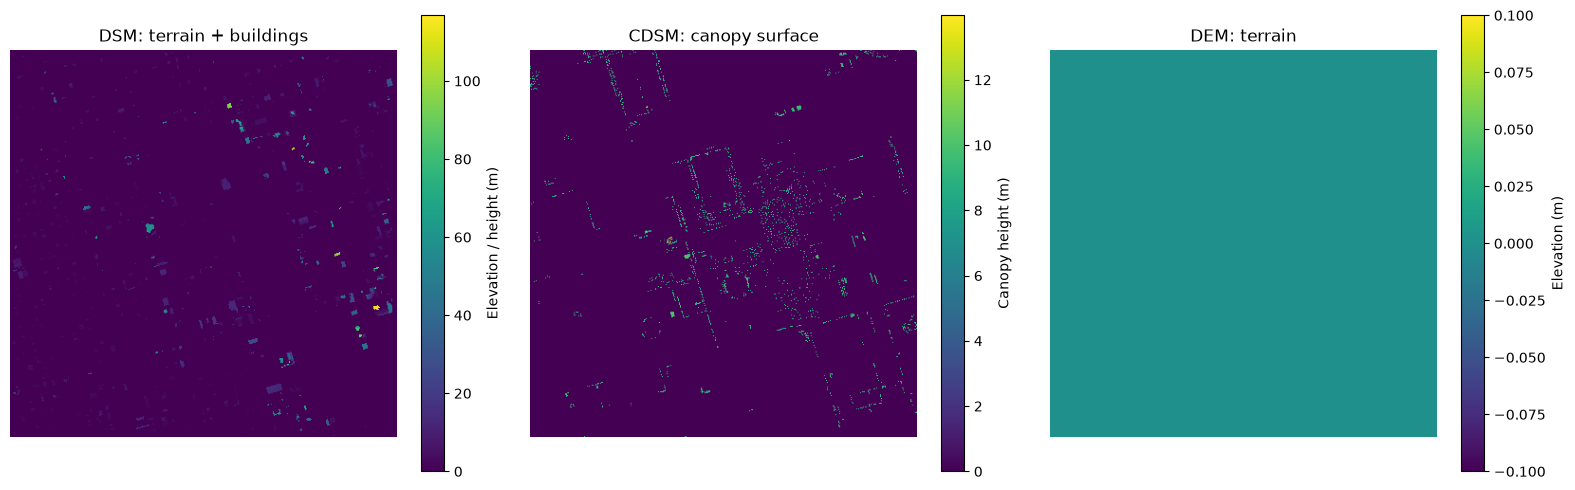

In [5]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5),
)

im0 = axes[0].imshow(
    dsm,
    origin="lower",
)

axes[0].set_title(
    "DSM: terrain + buildings"
)

plt.colorbar(
    im0,
    ax=axes[0],
    label="Elevation / height (m)",
)


im1 = axes[1].imshow(
    cdsm,
    origin="lower",
)

axes[1].set_title(
    "CDSM: canopy surface"
)

plt.colorbar(
    im1,
    ax=axes[1],
    label="Canopy height (m)",
)


im2 = axes[2].imshow(
    dem_surface,
    origin="lower",
)

axes[2].set_title(
    "DEM: terrain"
)

plt.colorbar(
    im2,
    ax=axes[2],
    label="Elevation (m)",
)

for ax in axes:
    ax.set_axis_off()

plt.tight_layout()
plt.show()

## 6. Recover the VoxCity geographic bounds

VoxCity stores the model bounds in its metadata.

The arrays are treated as WGS84 geographic grids before reprojection to
Toronto UTM Zone 17N.

In [6]:
SRC_CRS = "EPSG:4326"
DST_CRS = "EPSG:32617"
TARGET_RESOLUTION_M = 5

try:
    minlon, minlat, maxlon, maxlat = (
        vox.voxels.meta.bounds
    )
except Exception as exc:
    raise RuntimeError(
        "Could not read VoxCity geographic bounds from vox.voxels.meta.bounds."
    ) from exc

print("Source bounds:")
print("minlon:", minlon)
print("minlat:", minlat)
print("maxlon:", maxlon)
print("maxlat:", maxlat)

Source bounds:
minlon: -79.40864362272377
minlat: 43.65453519234437
maxlon: -79.38336793360907
maxlat: 43.67288422832106


## 7. Define the source geotransform

The VoxCity arrays represent the geographic rectangle bounded by the coordinates
above.

Raster row order is handled explicitly during reprojection.

In [7]:
src_height, src_width = dsm.shape

src_transform = from_bounds(
    minlon,
    minlat,
    maxlon,
    maxlat,
    src_width,
    src_height,
)

print("Source raster size:")
print("height:", src_height)
print("width :", src_width)

Source raster size:
height: 408
width : 408


## 8. Calculate the target 5 m Toronto UTM grid

In [8]:
(
    dst_transform,
    dst_width,
    dst_height,
) = calculate_default_transform(
    SRC_CRS,
    DST_CRS,
    src_width,
    src_height,
    minlon,
    minlat,
    maxlon,
    maxlat,
    resolution=TARGET_RESOLUTION_M,
)

print("Target CRS:", DST_CRS)
print("Target width :", dst_width)
print("Target height:", dst_height)
print("Target resolution:", TARGET_RESOLUTION_M, "m")
print(
    "Approximate target cells:",
    f"{dst_width * dst_height:,}",
)

Target CRS: EPSG:32617
Target width : 416
Target height: 416
Target resolution: 5 m
Approximate target cells: 173,056


## 9. Reproject the three surfaces

Two resampling strategies are used:

- **nearest-neighbour** for DSM and canopy surfaces, preserving abrupt building
  and vegetation boundaries;
- **bilinear** for DEM, which is a continuous terrain surface.

The VoxCity arrays are flipped vertically to match rasterio's north-up raster
convention.

In [9]:
def reproject_surface(
    array,
    resampling,
):
    destination = np.zeros(
        (
            dst_height,
            dst_width,
        ),
        dtype=np.float32,
    )

    # VoxCity row orientation differs from north-up raster convention.
    source = np.flipud(
        array
    ).astype(
        np.float32
    )

    reproject(
        source=source,
        destination=destination,
        src_transform=src_transform,
        src_crs=SRC_CRS,
        dst_transform=dst_transform,
        dst_crs=DST_CRS,
        resampling=resampling,
    )

    return destination


dsm_5m = reproject_surface(
    dsm,
    Resampling.nearest,
)

cdsm_5m = reproject_surface(
    cdsm,
    Resampling.nearest,
)

dem_5m = reproject_surface(
    dem_surface,
    Resampling.bilinear,
)

print("Reprojection complete.")

Reprojection complete.


## 10. Inspect the projected arrays

In [10]:
projected_summary = pd.DataFrame(
    {
        "layer": [
            "DSM",
            "CDSM",
            "DEM",
        ],
        "min": [
            float(np.nanmin(dsm_5m)),
            float(np.nanmin(cdsm_5m)),
            float(np.nanmin(dem_5m)),
        ],
        "mean": [
            float(np.nanmean(dsm_5m)),
            float(np.nanmean(cdsm_5m)),
            float(np.nanmean(dem_5m)),
        ],
        "max": [
            float(np.nanmax(dsm_5m)),
            float(np.nanmax(cdsm_5m)),
            float(np.nanmax(dem_5m)),
        ],
        "nonzero_cells": [
            int(np.count_nonzero(dsm_5m)),
            int(np.count_nonzero(cdsm_5m)),
            int(np.count_nonzero(dem_5m)),
        ],
    }
)

display(projected_summary)

,layer,min,mean,max,nonzero_cells
0,DSM,0.0,0.470333,116.820000,7671
1,CDSM,0.0,0.126081,13.978206,2413
2,DEM,0.0,0.000000,0.000000,0


## 11. Write projected GeoTIFFs

These are the primary outputs required by the next SOLWEIG preparation/run stage.

In [11]:
def write_geotiff(
    path,
    array,
):
    with rasterio.open(
        path,
        "w",
        driver="GTiff",
        height=array.shape[0],
        width=array.shape[1],
        count=1,
        dtype="float32",
        crs=DST_CRS,
        transform=dst_transform,
        compress="lzw",
    ) as dst:
        dst.write(
            array.astype(np.float32),
            1,
        )


dsm_path = (
    SOLWEIG_INPUT_DIR
    / "dsm.tif"
)

cdsm_path = (
    SOLWEIG_INPUT_DIR
    / "cdsm.tif"
)

dem_path = (
    SOLWEIG_INPUT_DIR
    / "dem.tif"
)

write_geotiff(
    dsm_path,
    dsm_5m,
)

write_geotiff(
    cdsm_path,
    cdsm_5m,
)

write_geotiff(
    dem_path,
    dem_5m,
)

print("Saved:")
print("-", dsm_path)
print("-", cdsm_path)
print("-", dem_path)

Saved:
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/interim/solweig/UOFT_PILOT/dsm.tif
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/interim/solweig/UOFT_PILOT/cdsm.tif
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/interim/solweig/UOFT_PILOT/dem.tif


## 12. Validate the written raster metadata

The three rasters should have:

- the same CRS;
- the same dimensions;
- the same transform;
- approximately 5 m × 5 m pixels.

In [12]:
validation_rows = []

for raster_path in [
    dsm_path,
    cdsm_path,
    dem_path,
]:
    with rasterio.open(
        raster_path
    ) as src:

        array = src.read(1)

        validation_rows.append(
            {
                "file": raster_path.name,
                "crs": str(src.crs),
                "width": src.width,
                "height": src.height,
                "resolution_x": src.res[0],
                "resolution_y": src.res[1],
                "min": float(np.nanmin(array)),
                "mean": float(np.nanmean(array)),
                "max": float(np.nanmax(array)),
            }
        )

validation = pd.DataFrame(
    validation_rows
)

display(validation)

,file,crs,width,height,resolution_x,resolution_y,min,mean,max
0,dsm.tif,EPSG:32617,416,416,5.0,5.0,0.0,0.470333,116.820000
1,cdsm.tif,EPSG:32617,416,416,5.0,5.0,0.0,0.126081,13.978206
2,dem.tif,EPSG:32617,416,416,5.0,5.0,0.0,0.000000,0.000000


## 13. Confirm that all rasters align exactly

In [13]:
raster_metadata = []

for raster_path in [
    dsm_path,
    cdsm_path,
    dem_path,
]:
    with rasterio.open(
        raster_path
    ) as src:

        raster_metadata.append(
            {
                "shape": src.shape,
                "crs": src.crs,
                "transform": src.transform,
                "bounds": src.bounds,
            }
        )

reference = raster_metadata[0]

for metadata in raster_metadata[1:]:

    assert (
        metadata["shape"]
        == reference["shape"]
    )

    assert (
        metadata["crs"]
        == reference["crs"]
    )

    assert (
        metadata["transform"]
        == reference["transform"]
    )

    assert (
        metadata["bounds"]
        == reference["bounds"]
    )

print(
    "✓ DSM, CDSM, and DEM align exactly."
)

✓ DSM, CDSM, and DEM align exactly.


## 14. Check the projected spatial dimensions

The pilot was defined as 2 km × 2 km. Small differences can occur because the
original geographic rectangle and projected UTM grid are not perfectly aligned,
but the resulting extent should remain close to the intended pilot size.

In [14]:
with rasterio.open(
    dsm_path
) as src:

    bounds = src.bounds

    raster_width_m = (
        bounds.right
        - bounds.left
    )

    raster_height_m = (
        bounds.top
        - bounds.bottom
    )

    raster_area_km2 = (
        raster_width_m
        * raster_height_m
        / 1_000_000
    )

dimension_summary = pd.DataFrame(
    {
        "metric": [
            "Width",
            "Height",
            "Area",
        ],
        "value": [
            raster_width_m,
            raster_height_m,
            raster_area_km2,
        ],
        "unit": [
            "m",
            "m",
            "km²",
        ],
    }
)

display(dimension_summary)

,metric,value,unit
0,Width,2080.0000,m
1,Height,2080.0000,m
2,Area,4.3264,km²


## 15. Visualize the final SOLWEIG input rasters

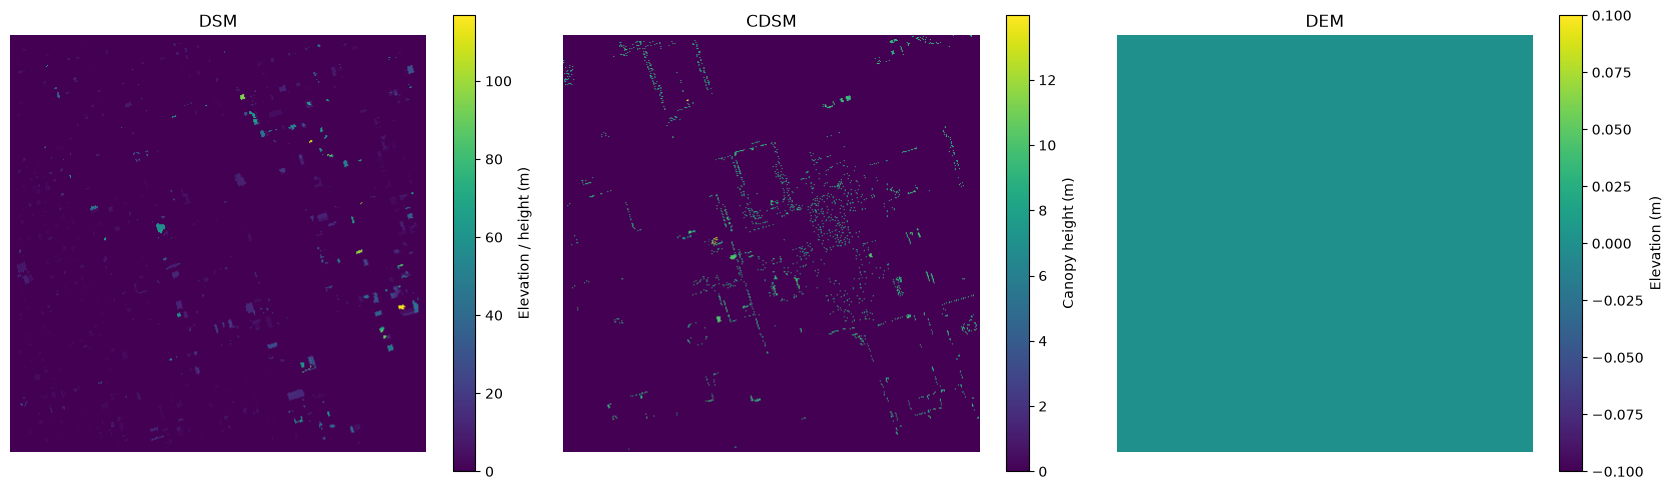

In [15]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(17, 5),
)

layers = [
    (
        dsm_5m,
        "DSM",
        "Elevation / height (m)",
    ),
    (
        cdsm_5m,
        "CDSM",
        "Canopy height (m)",
    ),
    (
        dem_5m,
        "DEM",
        "Elevation (m)",
    ),
]

for ax, (
    array,
    title,
    label,
) in zip(
    axes,
    layers,
):
    image = ax.imshow(
        array,
        origin="upper",
    )

    ax.set_title(
        title
    )

    ax.set_axis_off()

    plt.colorbar(
        image,
        ax=ax,
        label=label,
    )

plt.tight_layout()
plt.show()

## 16. Overlay the raster footprint with the U of T pilot boundary

This verifies that the rasterized thermal-model domain corresponds spatially
to the intended pilot.

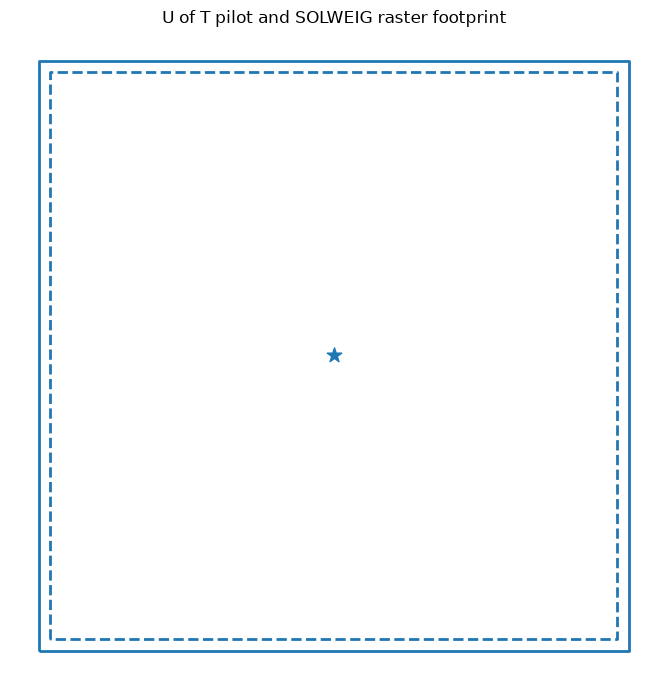

In [16]:
campus_center = gpd.read_file(
    TORONTO_RAW
    / "toronto_uoft_center.gpkg"
).to_crs(DST_CRS)

pilot_half_width_m = 1000

pilot_geometry = campus_center.geometry.iloc[0].buffer(
    pilot_half_width_m,
    cap_style=3,
)

pilot_area = gpd.GeoDataFrame(
    {
        "name": [
            "U of T pilot"
        ],
    },
    geometry=[pilot_geometry],
    crs=DST_CRS,
)

with rasterio.open(
    dsm_path
) as src:

    raster_footprint = gpd.GeoDataFrame(
        {
            "name": [
                "SOLWEIG raster"
            ],
        },
        geometry=[
            __import__(
                "shapely.geometry"
            ).geometry.box(
                src.bounds.left,
                src.bounds.bottom,
                src.bounds.right,
                src.bounds.top,
            )
        ],
        crs=src.crs,
    )

fig, ax = plt.subplots(
    figsize=(7, 7)
)

raster_footprint.boundary.plot(
    ax=ax,
    linewidth=2.0,
)

pilot_area.boundary.plot(
    ax=ax,
    linewidth=2.0,
    linestyle="--",
)

campus_center.plot(
    ax=ax,
    marker="*",
    markersize=120,
    zorder=10,
)

ax.set_title(
    "U of T pilot and SOLWEIG raster footprint"
)

ax.set_aspect("equal")
ax.set_axis_off()

plt.tight_layout()
plt.show()

## 17. Final input summary

In [17]:
final_summary = {
    "model": "UOFT_PILOT",
    "target_crs": DST_CRS,
    "target_resolution_m": TARGET_RESOLUTION_M,
    "raster_width_cells": dst_width,
    "raster_height_cells": dst_height,
    "raster_width_m": raster_width_m,
    "raster_height_m": raster_height_m,
    "dsm_max_m": float(
        np.nanmax(
            dsm_5m
        )
    ),
    "canopy_max_m": float(
        np.nanmax(
            cdsm_5m
        )
    ),
    "dem_min_m": float(
        np.nanmin(
            dem_5m
        )
    ),
    "dem_max_m": float(
        np.nanmax(
            dem_5m
        )
    ),
}

for key, value in final_summary.items():
    print(
        f"{key}: {value}"
    )

model: UOFT_PILOT
target_crs: EPSG:32617
target_resolution_m: 5
raster_width_cells: 416
raster_height_cells: 416
raster_width_m: 2080.0
raster_height_m: 2080.0
dsm_max_m: 116.81999969482422
canopy_max_m: 13.978205680847168
dem_min_m: 0.0
dem_max_m: 0.0


## Interpretation and next step

The U of T pilot is now represented by a common set of projected 5 m surfaces:

**Toronto municipal building heights + VoxCity urban form → DSM / CDSM / DEM**

Before running SOLWEIG, confirm that:

- the enriched DSM contains realistic Toronto building-height variation;
- canopy coverage is plausible;
- terrain elevation is realistic;
- all three rasters align perfectly;
- the raster footprint corresponds to the intended 2 km × 2 km pilot.

The next notebook should improve on the Sevilla PoC by using a **common-time
thermal scenario**, rather than immediately relying on cell-wise daily maximum
UTCI.

Continue to:

**`05_toronto_weather_and_solweig.ipynb`**